In [1]:
import matplotlib.pyplot as plt

In [2]:
!pip install pandas numpy matplotlib

'pip' is not recognized as an internal or external command,
operable program or batch file.


In [3]:
!pip install pandas numpy matplotlib

'pip' is not recognized as an internal or external command,
operable program or batch file.


In [4]:
import pandas as pd

df = pd.read_csv("agri_combined_datasets.csv")

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 6817
Number of columns: 25


In [5]:
df.columns

Index(['state', 'district', 'crop', 'year', 'area', 'production', 'yield',
       'annual_rainfall', 'n_high', 'n_medium', 'n_low', 'p_high', 'p_medium',
       'p_low', 'k_high', 'k_medium', 'k_low', 'oc_high', 'oc_medium',
       'oc_low', 'ph_alkaline', 'ph_acidic', 'ph_neutral', 'ec_nonsaline',
       'ec_saline'],
      dtype='str')

In [6]:
grouped = df.groupby(['state', 'crop'])

risk_df = grouped['yield'].agg(
    mean_yield='mean',
    std_yield='std'
).reset_index()

risk_df['CV'] = risk_df['std_yield'] / risk_df['mean_yield']

risk_df.head()

,state,crop,mean_yield,std_yield,CV
0,andhra pradesh,Cotton(lint),2.337013,1.082559,0.463223
1,andhra pradesh,Groundnut,1.895484,1.074582,0.566917
2,andhra pradesh,Maize,4.022179,1.314535,0.326822
3,andhra pradesh,Ragi,1.176512,0.414225,0.352079
4,andhra pradesh,Rice,3.161795,0.669033,0.211599


In [7]:
min_cv = risk_df['CV'].min()
max_cv = risk_df['CV'].max()

risk_df['CV_normalized'] = (risk_df['CV'] - min_cv) / (max_cv - min_cv)

risk_df.head()

,state,crop,mean_yield,std_yield,CV,CV_normalized
0,andhra pradesh,Cotton(lint),2.337013,1.082559,0.463223,0.138371
1,andhra pradesh,Groundnut,1.895484,1.074582,0.566917,0.195394
2,andhra pradesh,Maize,4.022179,1.314535,0.326822,0.063362
3,andhra pradesh,Ragi,1.176512,0.414225,0.352079,0.077252
4,andhra pradesh,Rice,3.161795,0.669033,0.211599,0.000000


In [8]:
def assign_risk(cv):
    if cv < 0.33:
        return 'Low'
    elif cv < 0.66:
        return 'Medium'
    else:
        return 'High'

risk_df['Risk_Category'] = risk_df['CV_normalized'].apply(assign_risk)

risk_df.head()

,state,crop,mean_yield,std_yield,CV,CV_normalized,Risk_Category
0,andhra pradesh,Cotton(lint),2.337013,1.082559,0.463223,0.138371,Low
1,andhra pradesh,Groundnut,1.895484,1.074582,0.566917,0.195394,Low
2,andhra pradesh,Maize,4.022179,1.314535,0.326822,0.063362,Low
3,andhra pradesh,Ragi,1.176512,0.414225,0.352079,0.077252,Low
4,andhra pradesh,Rice,3.161795,0.669033,0.211599,0.000000,Low


In [9]:
low_thresh = risk_df['CV_normalized'].quantile(0.33)
high_thresh = risk_df['CV_normalized'].quantile(0.66)

def assign_risk(cv):
    if cv < low_thresh:
        return 'Low'
    elif cv < high_thresh:
        return 'Medium'
    else:
        return 'High'

risk_df['Risk_Category'] = risk_df['CV_normalized'].apply(assign_risk)

risk_df.head()

,state,crop,mean_yield,std_yield,CV,CV_normalized,Risk_Category
0,andhra pradesh,Cotton(lint),2.337013,1.082559,0.463223,0.138371,Medium
1,andhra pradesh,Groundnut,1.895484,1.074582,0.566917,0.195394,High
2,andhra pradesh,Maize,4.022179,1.314535,0.326822,0.063362,Low
3,andhra pradesh,Ragi,1.176512,0.414225,0.352079,0.077252,Medium
4,andhra pradesh,Rice,3.161795,0.669033,0.211599,0.000000,Low


In [10]:
risk_distribution = risk_df['Risk_Category'].value_counts()
print(risk_distribution)

Risk_Category
High      9
Medium    8
Low       8
Name: count, dtype: int64


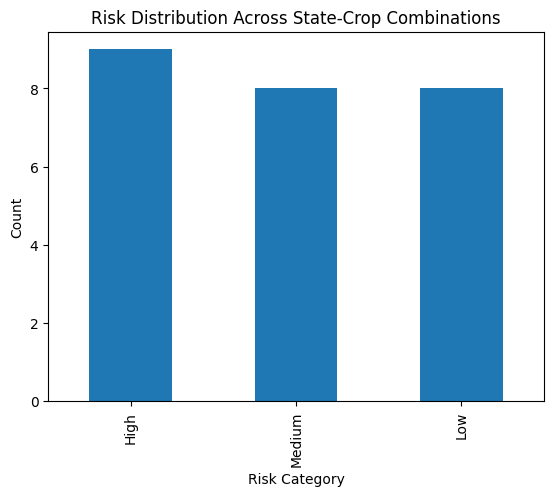

In [11]:
risk_distribution.plot(kind='bar')
plt.title("Risk Distribution Across State-Crop Combinations")
plt.xlabel("Risk Category")
plt.ylabel("Count")
plt.show()

Risk_Category
High      9
Medium    8
Low       8
Name: count, dtype: int64


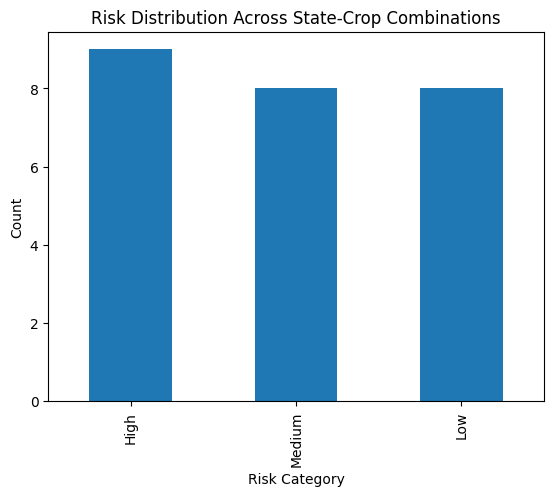

In [12]:
import matplotlib.pyplot as plt

risk_distribution = risk_df['Risk_Category'].value_counts()

print(risk_distribution)

risk_distribution.plot(kind='bar')
plt.title("Risk Distribution Across State-Crop Combinations")
plt.xlabel("Risk Category")
plt.ylabel("Count")
plt.show()

The risk distribution across state–crop combinations is fairly balanced, with high-risk cases slightly dominating. This indicates that a significant portion of agricultural systems exhibit considerable variability, highlighting the importance of risk-aware decision-making

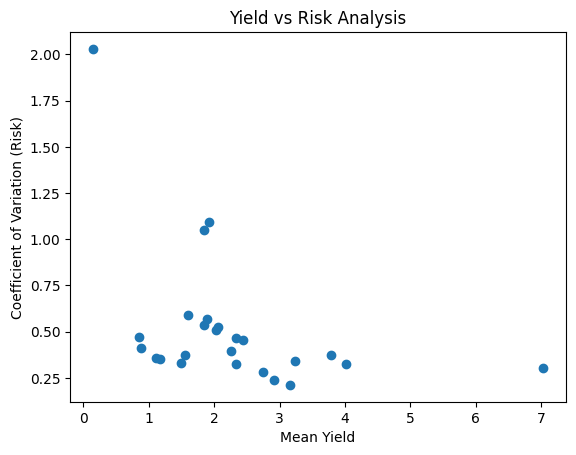

In [13]:
plt.scatter(risk_df['mean_yield'], risk_df['CV'])
plt.xlabel("Mean Yield")
plt.ylabel("Coefficient of Variation (Risk)")
plt.title("Yield vs Risk Analysis")
plt.show()

In [14]:
correlation = risk_df['mean_yield'].corr(risk_df['CV'])
print("Correlation between Yield and Risk:", correlation)

Correlation between Yield and Risk: -0.42654451269499105


The negative correlation (-0.426) between mean yield and coefficient of variation indicates that higher-yielding crops tend to be more stable and less risky. This suggests that improving agricultural productivity may also contribute to reducing yield variability, thereby lowering risk for farmers.However, the relationship is not perfectly strong, indicating that some high-yield crops may still exhibit variability, and risk cannot be assessed based on yield alone.

In [15]:
df.columns

Index(['state', 'district', 'crop', 'year', 'area', 'production', 'yield',
       'annual_rainfall', 'n_high', 'n_medium', 'n_low', 'p_high', 'p_medium',
       'p_low', 'k_high', 'k_medium', 'k_low', 'oc_high', 'oc_medium',
       'oc_low', 'ph_alkaline', 'ph_acidic', 'ph_neutral', 'ec_nonsaline',
       'ec_saline'],
      dtype='str')

In [16]:
rainfall_df = df.groupby(['state', 'crop'])['annual_rainfall'].mean().reset_index()

# Merge with risk_df
merged = pd.merge(risk_df, rainfall_df, on=['state', 'crop'])

merged.head()

,state,crop,mean_yield,std_yield,CV,CV_normalized,Risk_Category,annual_rainfall
0,andhra pradesh,Cotton(lint),2.337013,1.082559,0.463223,0.138371,Medium,1022.937013
1,andhra pradesh,Groundnut,1.895484,1.074582,0.566917,0.195394,High,1020.969032
2,andhra pradesh,Maize,4.022179,1.314535,0.326822,0.063362,Low,1023.689103
3,andhra pradesh,Ragi,1.176512,0.414225,0.352079,0.077252,Medium,1039.817829
4,andhra pradesh,Rice,3.161795,0.669033,0.211599,0.000000,Low,1023.689103


In [17]:
df['annual_rainfall'].dtype

dtype('float64')

In [18]:
df['annual_rainfall'] = pd.to_numeric(df['annual_rainfall'], errors='coerce')

In [19]:
df['annual_rainfall'].dtype

dtype('float64')

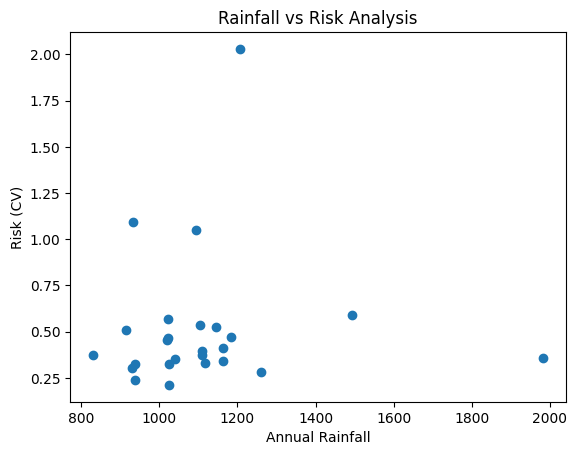

Correlation between Rainfall and Risk: 0.04479550847450743


In [20]:
rainfall_df = df.groupby(['state', 'crop'])['annual_rainfall'].mean().reset_index()

merged = pd.merge(risk_df, rainfall_df, on=['state', 'crop'])

# Plot
plt.scatter(merged['annual_rainfall'], merged['CV'])
plt.xlabel("Annual Rainfall")
plt.ylabel("Risk (CV)")
plt.title("Rainfall vs Risk Analysis")
plt.show()

# Correlation
rain_corr = merged['annual_rainfall'].corr(merged['CV'])
print("Correlation between Rainfall and Risk:", rain_corr)

The correlation between rainfall and yield variability is very weak (0.038), indicating that rainfall alone does not significantly influence agricultural risk. This suggests that other factors such as soil conditions, fertilizer usage, and farming practices may play a more important role in determining yield stability. While rainfall was hypothesized to influence yield variability in Week 3, the analysis shows that its impact is limited when considered independently.

In [21]:
risk_df['Yield_Rank'] = risk_df['mean_yield'].rank(ascending=False)

In [22]:
risk_df['Stability_Score'] = risk_df['mean_yield'] / risk_df['CV']

In [23]:
risk_df['Stability_Rank'] = risk_df['Stability_Score'].rank(ascending=False)

In [24]:
risk_df[['state', 'crop', 'mean_yield', 'CV', 'Yield_Rank', 'Stability_Rank']].head(10)

,state,crop,mean_yield,CV,Yield_Rank,Stability_Rank
0,andhra pradesh,Cotton(lint),2.337013,0.463223,9.0,11.0
1,andhra pradesh,Groundnut,1.895484,0.566917,15.0,17.0
2,andhra pradesh,Maize,4.022179,0.326822,2.0,3.0
3,andhra pradesh,Ragi,1.176512,0.352079,21.0,18.0
4,andhra pradesh,Rice,3.161795,0.211599,5.0,2.0
5,karnataka,Cotton(lint),2.437701,0.455590,8.0,10.0
6,karnataka,Groundnut,0.886019,0.413738,23.0,21.0
7,karnataka,Maize,3.237304,0.342573,4.0,7.0
8,karnataka,Ragi,1.485261,0.332036,20.0,12.0
9,karnataka,Rice,2.738364,0.280255,7.0,6.0


The comparison between yield-based ranking and stability-based ranking reveals significant differences. Certain crops, such as rice, improve in ranking when stability is considered due to their low variability, while others like cotton and groundnut drop in ranking due to higher risk. This demonstrates that high yield alone is not a sufficient criterion for agricultural decision-making

In [25]:
def new_risk(cv):
    if cv < 0.30:
        return 'Low'
    elif cv < 0.70:
        return 'Medium'
    else:
        return 'High'

risk_df['New_Risk_Category'] = risk_df['CV_normalized'].apply(new_risk)

In [26]:
changes = (risk_df['Risk_Category'] != risk_df['New_Risk_Category']).sum()

print("Number of changes:", changes)

Number of changes: 16


In [27]:
risk_df[['Risk_Category', 'New_Risk_Category']].value_counts()

Risk_Category  New_Risk_Category
Medium         Low                  8
Low            Low                  8
High           Low                  6
               Medium               2
               High                 1
Name: count, dtype: int64

In [28]:
risk_df['state'].unique()

<StringArray>
['andhra pradesh', 'karnataka', 'madhya pradesh', 'maharashtra', 'tamil nadu']
Length: 5, dtype: str

The sensitivity analysis shows that 16 state–crop combinations changed their risk category when thresholds were adjusted. A large number of observations shifted towards the low-risk category, indicating that the classification is somewhat sensitive to threshold selection